# 02 · Model quality (automatic)

Measures the three AI parts of the app **through the app's own code** (`app/models.py`), on the 100 held-out COCO images from notebook 01:

| Part | Question | Metrics |
|---|---|---|
| **A. SAM click-to-segment** (AI outline) | How good is the outline after 1, 2, ... 5 clicks? How many clicks until it is good? | mIoU@k, NoC@85, NoC@90, box-prompt IoU |
| **B. Detectors** (suggestions) | How well do YOLO11n and YOLOE find COCO's objects? | COCO mAP (AP, AP50, AP75, by size), precision / recall / F1 at the UI's 35% |
| **C. YOLO → SAM** (accepting a suggestion) | When a suggestion is right, how good is the outline SAM draws from its box? | mask IoU |

Clicks are **simulated** with the standard protocol from interactive-segmentation research (RITM, SimpleClick): the first click goes to the point deepest inside the object; every next click goes to the deepest point of the biggest mistake, positive where the object was missed, negative where the outline spilled over. This is what a careful user does, but repeatable.

Runtime on CPU: roughly 10-15 minutes. Results are saved to `eval/results/`.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "eval" else pathlib.Path.cwd()))
from eval import evallib as E
E.setup()          # work from the project folder, where the model weights are
print("project folder:", E.ROOT)

project folder: C:\Users\yuvra\Desktop\UNI\Ai Vision\AI annotator


In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, json
RES = E.EVAL / "results"; RES.mkdir(exist_ok=True)
coco = E.load_coco()
S = E.load_subsets()
IMGS = S["model"]
print(len(IMGS), "images,", len(coco.getAnnIds(imgIds=IMGS, iscrowd=False)), "objects")

loading annotations into memory...
Done (t=0.61s)
creating index...
index created!
100 images, 690 objects


## A. SAM click-to-segment

Up to 300 objects (at least 16×16 px), 5 simulated clicks each, plus one box prompt from the true box.

In [3]:
sam = pd.DataFrame(E.eval_sam(coco, IMGS, max_instances=300, max_clicks=5))
sam.to_csv(RES / "sam_clicks.csv", index=False)
len(sam)

c:\Users\yuvra\Desktop\UNI\Ai Vision\AI annotator\.venv311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
SAM objects:   0%|          | 0/300 [00:00<?, ?it/s]

Ultralytics 8.4.187  Python-3.11.9 torch-2.14.1+cpu CPU (12th Gen Intel Core i7-12700H)


SAM objects: 100%|██████████| 300/300 [03:24<00:00,  1.46it/s]


300

In [4]:
k_cols = [f"iou@{k}" for k in range(1, 6)]
summary = pd.Series({
    **{f"mIoU after {k} click{'s' if k > 1 else ''}": sam[f"iou@{k}"].mean() for k in range(1, 6)},
    "mIoU from a box": sam["iou_box"].mean(),
    "NoC@85 (mean clicks)": sam["noc85"].mean(),
    "reached 85% within 5 clicks": sam["reached85"].mean(),
    "NoC@90 (mean clicks)": sam["noc90"].mean(),
    "reached 90% within 5 clicks": sam["reached90"].mean(),
    "image encode, median s": sam.drop_duplicates("image_id")["encode_ms"].median() / 1000,
    "per click, median s": sam["decode_ms_mean"].median() / 1000,
}).round(3)
summary

mIoU after 1 click             0.569
mIoU after 2 clicks            0.654
mIoU after 3 clicks            0.728
mIoU after 4 clicks            0.758
mIoU after 5 clicks            0.775
mIoU from a box                0.779
NoC@85 (mean clicks)           3.450
reached 85% within 5 clicks    0.520
NoC@90 (mean clicks)           4.093
reached 90% within 5 clicks    0.340
image encode, median s         0.830
per click, median s            0.066
dtype: float64

In [5]:
# By object size (COCO's small < 32x32 <= medium < 96x96 <= large)
sam.groupby("size")[["iou@1", "iou@3", "iou@5", "iou_box", "noc90"]].mean().round(3).join(sam["size"].value_counts().rename("objects"))

,iou@1,iou@3,iou@5,iou_box,noc90,objects
size,,,,,,
large,0.594,0.794,0.827,0.838,3.315,92
medium,0.570,0.728,0.779,0.773,4.150,133
small,0.537,0.645,0.705,0.717,4.947,75


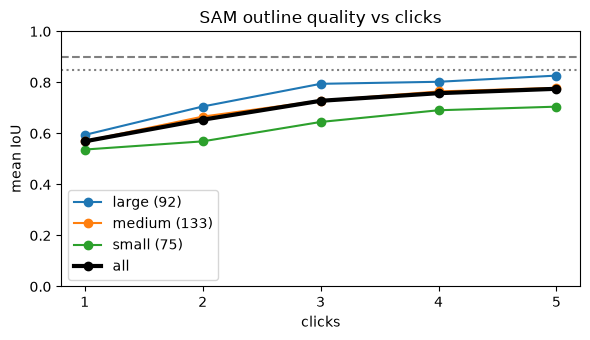

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for size, g in sam.groupby("size"):
    ax.plot(range(1, 6), g[k_cols].mean().values, marker="o", label=f"{size} ({len(g)})")
ax.plot(range(1, 6), sam[k_cols].mean().values, marker="o", lw=3, color="black", label="all")
ax.axhline(0.85, ls=":", color="grey"); ax.axhline(0.90, ls="--", color="grey")
ax.set(xlabel="clicks", ylabel="mean IoU", title="SAM outline quality vs clicks", ylim=(0, 1), xticks=range(1, 6))
ax.legend(); plt.tight_layout(); fig.savefig(RES / "sam_iou_vs_clicks.png", dpi=150)

## B. Detectors: YOLO11n vs YOLOE

Both are asked for the 80 COCO class names. For YOLO11n those are its own classes; for YOLOE they are text prompts, so this is a **zero-shot** test (it never trained on COCO's label set). Detections down to 1% confidence go into COCO mAP (the metric needs the whole ranking); precision/recall are then read at **35%**, the app's default slider.

In [7]:
from app.models import Detector
det = Detector()
runs = {}
for key in ("yolo11n", "yoloe"):
    dets, ms = E.run_detector(det, key, coco, IMGS, conf=0.01)
    runs[key] = (dets, ms)
    json.dump(dets, open(RES / f"detections_{key}.json", "w"))
{k: len(v[0]) for k, v in runs.items()}

yoloe:   0%|          | 0/100 [00:00<?, ?it/s]c:\Users\yuvra\Desktop\UNI\Ai Vision\AI annotator\.venv311\Lib\site-packages\torch\jit\_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
yoloe: 100%|██████████| 100/100 [00:25<00:00,  3.96it/s]


{'yolo11n': 3416, 'yoloe': 3572}

In [8]:
rows = {}
for key, (dets, ms) in runs.items():
    print(f"\n===== {key} =====")
    m = E.coco_map(coco, dets, IMGS)
    pr = E.precision_recall_at(coco, dets, IMGS, conf=0.35)
    rows[key] = {**m, **{f"{k}@35%": pr[k] for k in ("precision", "recall", "f1")},
                 "false alarms@35% per image": pr["false_alarms"] / len(IMGS),
                 "median s per image": np.median(ms) / 1000}
det_table = pd.DataFrame(rows).round(3)
det_table.to_csv(RES / "detectors.csv")
det_table


===== yolo11n =====
Loading and preparing results...
DONE (t=0.01s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.41s).
Accumulating evaluation results...
DONE (t=0.28s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.488
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.643
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.524
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.249
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.541
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.701
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.387
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.543
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.572
 Average Recall     (AR) @[ IoU=0.50:0.95 | are

,yolo11n,yoloe
AP,0.488,0.441
AP50,0.643,0.607
AP75,0.524,0.476
AP_small,0.249,0.206
AP_medium,0.541,0.488
AP_large,0.701,0.644
AR100,0.572,0.549
precision@35%,0.775,0.702
recall@35%,0.486,0.448
f1@35%,0.597,0.547


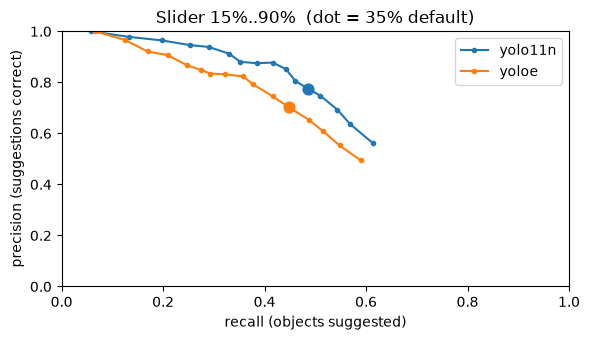

In [9]:
# Precision and recall across the slider: what moving it trades off
grid = np.arange(0.15, 0.91, 0.05)
fig, ax = plt.subplots(figsize=(6, 3.5))
for key, (dets, _) in runs.items():
    prs = [E.precision_recall_at(coco, dets, IMGS, conf=c) for c in grid]
    ax.plot([p["recall"] for p in prs], [p["precision"] for p in prs], marker=".", label=key)
    p35 = E.precision_recall_at(coco, dets, IMGS, conf=0.35)
    ax.scatter([p35["recall"]], [p35["precision"]], s=60, zorder=3)
ax.set(xlabel="recall (objects suggested)", ylabel="precision (suggestions correct)",
       title="Slider 15%..90%  (dot = 35% default)", xlim=(0, 1), ylim=(0, 1))
ax.legend(); plt.tight_layout(); fig.savefig(RES / "detectors_pr.png", dpi=150)

## C. Accepting a correct suggestion: YOLO → SAM

For suggestions at 35% that match a real object, send the box to SAM, exactly as the app does on accept, and compare SAM's outline with the true outline.

In [10]:
pipe = {}
for key, (dets, _) in runs.items():
    _, matches = E.precision_recall_at(coco, dets, IMGS, conf=0.35, with_matches=True)
    pipe[key] = pd.DataFrame(E.eval_pipeline(coco, matches, max_n=150))
    pipe[key].to_csv(RES / f"pipeline_{key}.csv", index=False)
pd.DataFrame({k: {"outlines": len(v), "mean mask IoU": v["mask_iou"].mean(),
                  "share >= 0.75": (v["mask_iou"] >= 0.75).mean()} for k, v in pipe.items()}).round(3)

YOLO -> SAM:   0%|          | 0/150 [00:00<?, ?it/s]

Ultralytics 8.4.187  Python-3.11.9 torch-2.14.1+cpu CPU (12th Gen Intel Core i7-12700H)


YOLO -> SAM:   0%|          | 0/150 [00:00<?, ?it/s]

Ultralytics 8.4.187  Python-3.11.9 torch-2.14.1+cpu CPU (12th Gen Intel Core i7-12700H)


YOLO -> SAM: 100%|██████████| 150/150 [01:06<00:00,  2.27it/s]


,yolo11n,yoloe
outlines,150.000,150.00
mean mask IoU,0.786,0.78
share >= 0.75,0.713,0.70


## D. Clicks: tracing by hand vs SAM (supporting number)

COCO's annotators traced each outline point by point; the number of polygon vertices is a fair proxy for the clicks a manual outline costs. Compare it with the clicks SAM needed to reach 90% IoU. This is a *model-based estimate*; the measured effort comes from notebook 03.

In [11]:
v = sam.dropna(subset=["gt_vertices"])
pd.Series({"median vertices in a COCO outline": v["gt_vertices"].median(),
           "mean SAM clicks to 90% (capped at 5)": v["noc90"].mean(),
           "objects SAM got to 90% in <= 5 clicks": v["reached90"].mean()}).round(2)

median vertices in a COCO outline        21.50
mean SAM clicks to 90% (capped at 5)      4.09
objects SAM got to 90% in <= 5 clicks     0.34
dtype: float64

In [12]:
# Everything in one file for the report
json.dump({"sam": summary.to_dict(), "detectors": det_table.to_dict(),
           "pipeline": {k: float(v["mask_iou"].mean()) for k, v in pipe.items()}},
          open(RES / "model_quality.json", "w"), indent=1)
print("saved to", RES)

saved to C:\Users\yuvra\Desktop\UNI\Ai Vision\AI annotator\eval\results
